# 03 — Post-Cleaning Waveform Integrity & NeuroKit2 Validation

Checks RMS amplitude, Einthoven lead physics (`II = I + III`), residual mains hum, and `NeuroKit2` `500 Hz` R-peak heart rate across all five sources in the combined dataset.

,rms_ii_mv,einthoven_rmse_mv,lf_wander_pct,mains_50_60_pct,hf_gt40_pct
source_dataset,,,,,
chapman_shaoxing,0.1209,0.0003,0.071,0.0,0.063
code15,0.2397,0.0001,0.084,0.0,0.014
georgia_ecg,0.1246,0.0005,0.061,0.0,0.039
mimic_iv_ecg,0.1130,0.0003,0.046,0.0,0.050
ptbxl,0.1196,0.0001,0.033,0.0,0.038


/nfs/data8/schlegel/git/ecg-data-repo/combined/dataset.py:78: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(meta_path)


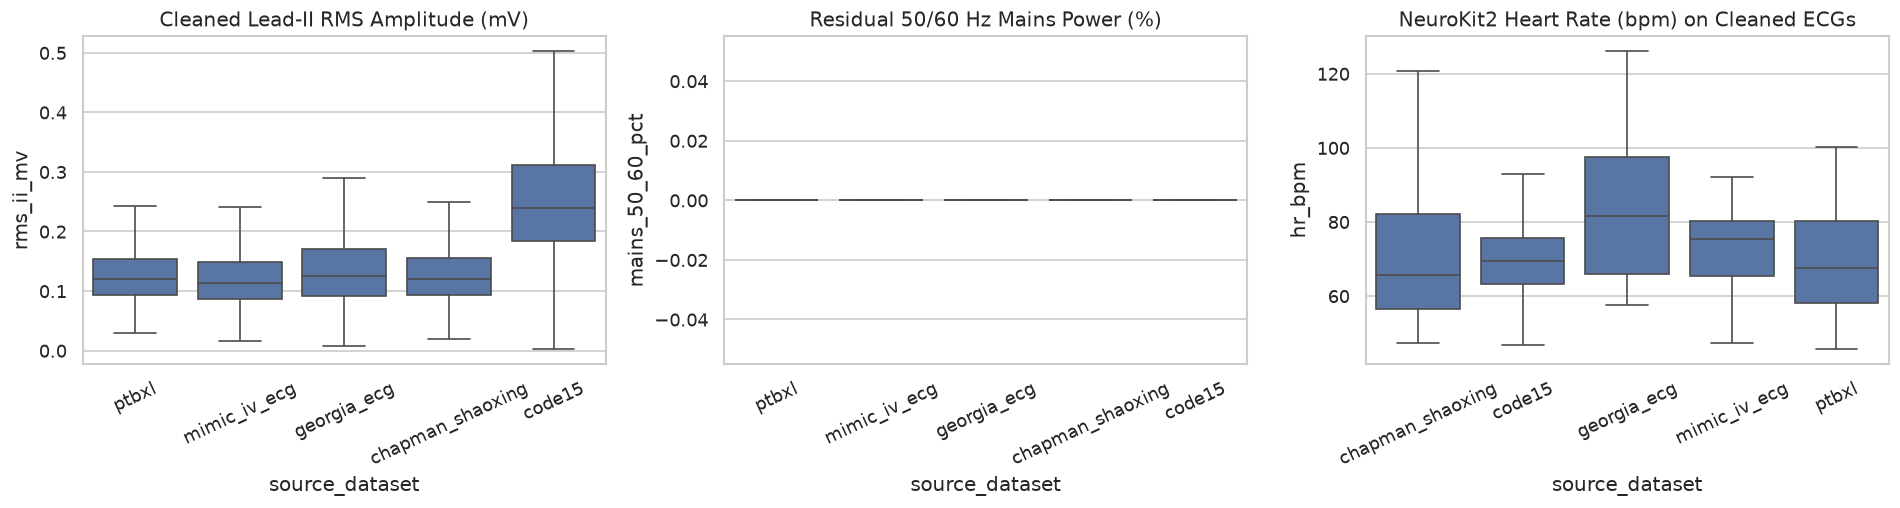

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "combined" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate combined/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from combined import CombinedECGDataset
COMBINED_DIR = REPO_ROOT / "combined"
DATA_DIR = COMBINED_DIR / "data"
QUALITY_DIR = COMBINED_DIR / "quality"
LEADS = CombinedECGDataset.LEADS

import neurokit2 as nk

err = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz")
display(err.groupby("source_dataset")[["rms_ii_mv", "einthoven_rmse_mv", "lf_wander_pct", "mains_50_60_pct", "hf_gt40_pct"]].median().round(4))

ds = CombinedECGDataset()
hr_rows = []
rng = np.random.default_rng(42)
for src in sorted(ds._df["source_dataset"].unique()):
    idxs = ds._df.index[ds._df["source_dataset"] == src].to_numpy()
    picks = rng.choice(idxs, size=min(40, len(idxs)), replace=False)
    for idx in picks:
        sig = ds[int(idx)]["signal"][1]
        try:
            _, info = nk.ecg_peaks(sig, sampling_rate=500)
            rpeaks = info["ECG_R_Peaks"]
            if len(rpeaks) >= 3:
                hr = 60.0 / (np.median(np.diff(rpeaks)) / 500.0)
                if 25 <= hr <= 220:
                    hr_rows.append({"source_dataset": src, "hr_bpm": hr})
        except Exception:
            pass

hr_df = pd.DataFrame(hr_rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.boxplot(data=err, x="source_dataset", y="rms_ii_mv", showfliers=False, ax=axes[0])
axes[0].set_title("Cleaned Lead-II RMS Amplitude (mV)")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=err, x="source_dataset", y="mains_50_60_pct", showfliers=False, ax=axes[1])
axes[1].set_title("Residual 50/60 Hz Mains Power (%)")
axes[1].tick_params(axis="x", rotation=25)

sns.boxplot(data=hr_df, x="source_dataset", y="hr_bpm", showfliers=False, ax=axes[2])
axes[2].set_title("NeuroKit2 Heart Rate (bpm) on Cleaned ECGs")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()
